In [9]:
from pathlib import Path
import pandas as pd

# Works whether the notebook starts in the repo or stage_iv folder.
folder = Path(
    "/Users/andykim/Desktop/ucsd/dsc-capstone/"
    "DSC180---Rainfall/stage_iv"
)

df = pd.read_csv(
    folder / "data" / "san_diego_stage_iv_jan21_23_2024.csv"
)

df["hour_end_utc"] = pd.to_datetime(df["hour_end_utc"], utc=True)
df["hour_end_pacific"] = (
    df["hour_end_utc"].dt.tz_convert("America/Los_Angeles")
)

display(df.head(30))
display(df["rainfall_mm"].describe())

print("Hours:", df["hour_end_utc"].nunique())  # Expect 72
print("Missing rainfall:", df["rainfall_mm"].isna().mean())
print("Duplicate grid-cell hours:",
      df.duplicated(["hour_end_utc", "latitude", "longitude"]).sum())

,hour_end_utc,hour_end_pacific,latitude,longitude,rainfall_mm
0,2024-01-21 09:00:00+00:00,2024-01-21 01:00:00-08:00,32.405233,-116.112681,NaN
1,2024-01-21 09:00:00+00:00,2024-01-21 01:00:00-08:00,32.412015,-116.071704,NaN
2,2024-01-21 09:00:00+00:00,2024-01-21 01:00:00-08:00,32.418773,-116.030716,NaN
3,2024-01-21 09:00:00+00:00,2024-01-21 01:00:00-08:00,32.405517,-116.325585,NaN
4,2024-01-21 09:00:00+00:00,2024-01-21 01:00:00-08:00,32.412428,-116.284638,NaN
5,2024-01-21 09:00:00+00:00,2024-01-21 01:00:00-08:00,32.419315,-116.243679,NaN
6,2024-01-21 09:00:00+00:00,2024-01-21 01:00:00-08:00,32.426177,-116.202709,NaN
7,2024-01-21 09:00:00+00:00,2024-01-21 01:00:00-08:00,32.433015,-116.161727,NaN
8,2024-01-21 09:00:00+00:00,2024-01-21 01:00:00-08:00,32.439829,-116.120734,NaN
9,2024-01-21 09:00:00+00:00,2024-01-21 01:00:00-08:00,32.446618,-116.079729,NaN


count    73584.000000
mean         0.746082
std          1.942513
min          0.000000
25%          0.000000
50%          0.040000
75%          0.590000
max         60.960000
Name: rainfall_mm, dtype: float64

Hours: 72
Missing rainfall: 0.24742268041237114
Duplicate grid-cell hours: 0


In [11]:
target = pd.Timestamp(
    "2024-01-22 10:00:00",
    tz="America/Los_Angeles"
)

observations = df.loc[
    (df["hour_end_pacific"] == target)
    & df["rainfall_mm"].notna()
].copy()

observations["rainfall_inches"] = observations["rainfall_mm"] / 25.4

display(
    observations.sort_values("rainfall_mm", ascending=False).head(10)
)

,hour_end_utc,hour_end_pacific,latitude,longitude,rainfall_mm,rainfall_inches
45284,2024-01-22 18:00:00+00:00,2024-01-22 10:00:00-08:00,32.760039,-117.183631,40.39,1.590157
45285,2024-01-22 18:00:00+00:00,2024-01-22 10:00:00-08:00,32.767492,-117.142511,39.37,1.550000
45283,2024-01-22 18:00:00+00:00,2024-01-22 10:00:00-08:00,32.752561,-117.224740,37.08,1.459843
45286,2024-01-22 18:00:00+00:00,2024-01-22 10:00:00-08:00,32.774920,-117.101377,36.07,1.420079
45282,2024-01-22 18:00:00+00:00,2024-01-22 10:00:00-08:00,32.745060,-117.265835,35.05,1.379921
45287,2024-01-22 18:00:00+00:00,2024-01-22 10:00:00-08:00,32.782324,-117.060231,33.27,1.309843
45490,2024-01-22 18:00:00+00:00,2024-01-22 10:00:00-08:00,32.940533,-117.186914,33.02,1.300000
45491,2024-01-22 18:00:00+00:00,2024-01-22 10:00:00-08:00,32.948001,-117.145639,32.77,1.290157
45489,2024-01-22 18:00:00+00:00,2024-01-22 10:00:00-08:00,32.933041,-117.228176,32.77,1.290157
45281,2024-01-22 18:00:00+00:00,2024-01-22 10:00:00-08:00,32.737534,-117.306917,32.26,1.270079


In [2]:
print(df.columns)

Index(['hour_end_utc', 'hour_end_pacific', 'latitude', 'longitude',
       'rainfall_mm'],
      dtype='str')


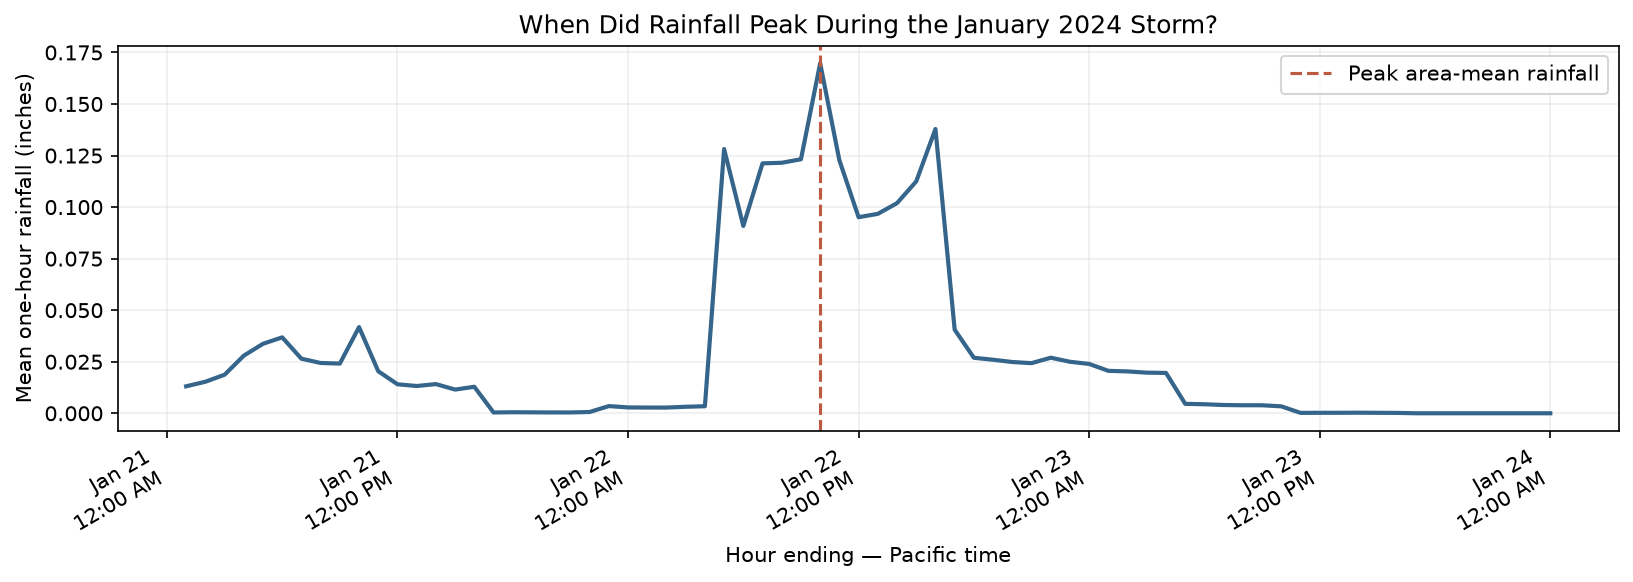

Peak hour ends: 2024-01-22 10:00:00-08:00
Peak area-mean rainfall: 0.17 inches


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from zoneinfo import ZoneInfo

hourly = (
    df.groupby("hour_end_pacific")["rainfall_mm"]
    .mean()
    .sort_index()
    / 25.4
)

peak = hourly.idxmax()

fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(hourly.index, hourly.values, color="#35658a", linewidth=2)
ax.axvline(peak, color="#bd5b42", linestyle="--", label="Peak area-mean rainfall")

ax.set(
    title="When Did Rainfall Peak During the January 2024 Storm?",
    xlabel="Hour ending — Pacific time",
    ylabel="Mean one-hour rainfall (inches)",
)

pacific = ZoneInfo("America/Los_Angeles")
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12], tz=pacific))
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %d\n%I:%M %p", tz=pacific)
)

ax.legend()
ax.grid(alpha=0.2)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

print("Peak hour ends:", peak)
print("Peak area-mean rainfall:", round(hourly.max(), 2), "inches")

## Screening for localized extreme rainfall
This plot shows the highest available Stage IV grid-cell estimate each hour, rather than the regional mean. The location can change each hour. The 1.2–1.5 inch range comes from Tyler's project guidance for locations west of the mountains. Exceedances are candidates requiring location and gauge checks, not confirmed countywide extremes. This figure does not evaluate the separate three-hour flag or establish mountain blocking.


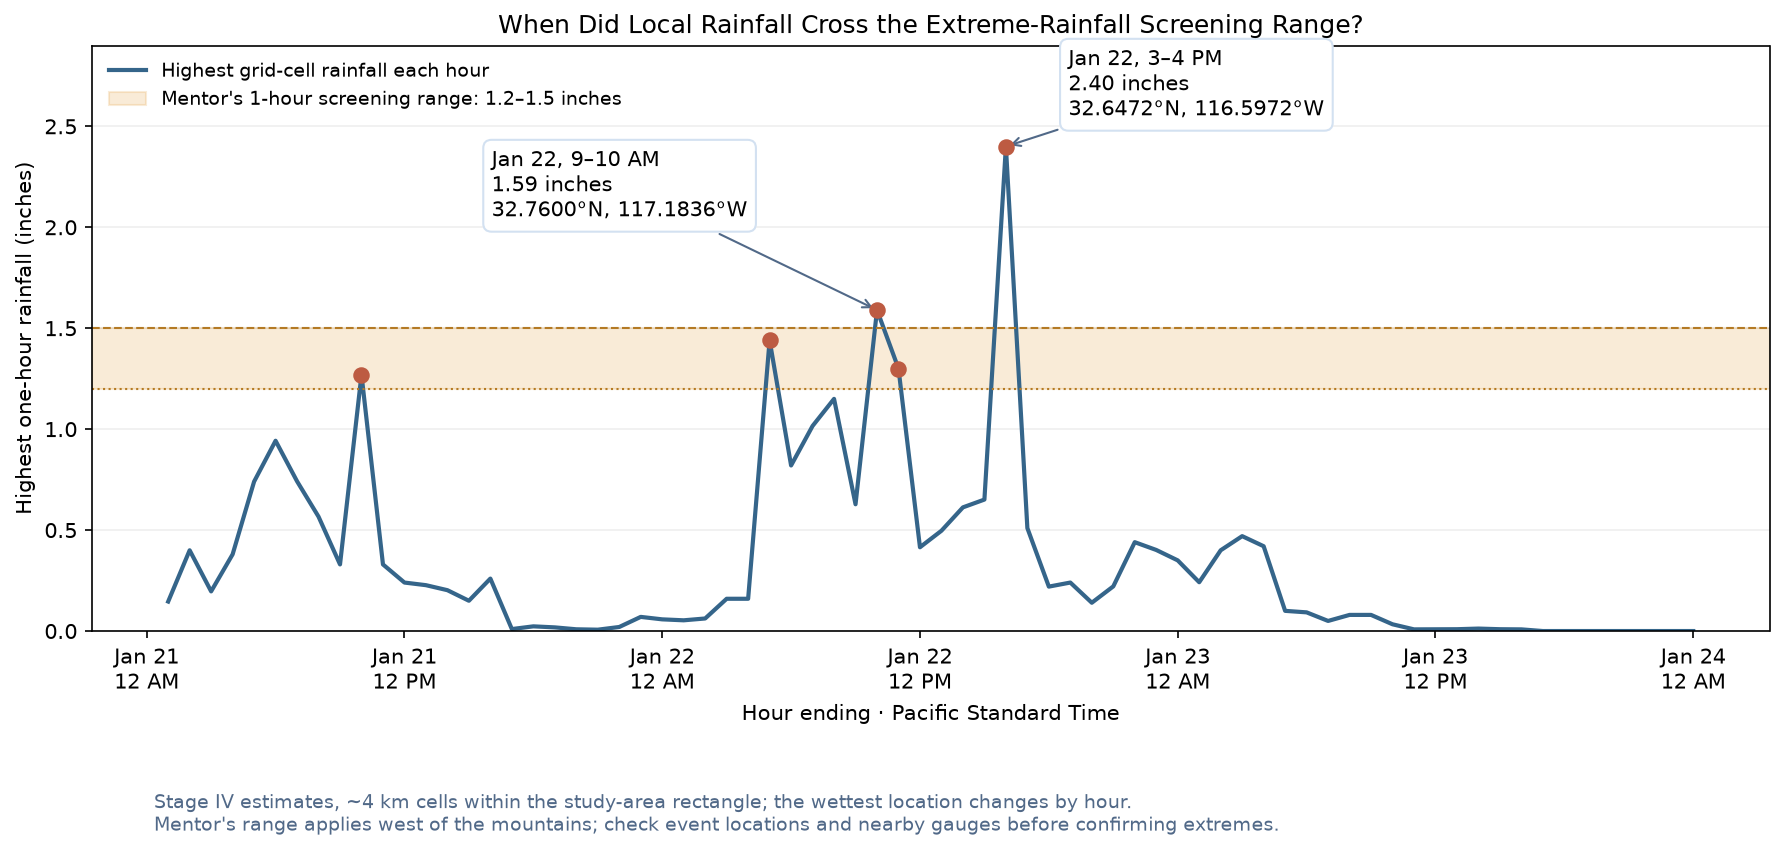

In [ ]:
from pathlib import Path
from zoneinfo import ZoneInfo
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Find the repository whether this notebook runs from data/, stage_iv/, or the root.
repo = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "stage_iv/data/san_diego_stage_iv_jan21_23_2024.csv").exists())
rain = pd.read_csv(repo / "stage_iv/data/san_diego_stage_iv_jan21_23_2024.csv")
rain["hour_end_pacific"] = pd.to_datetime(rain["hour_end_utc"], utc=True).dt.tz_convert("America/Los_Angeles")
rain["rainfall_inches"] = rain["rainfall_mm"] / 25.4

# Retain the location of the maximum; this may change between hours.
valid = rain.dropna(subset=["rainfall_inches"])
wettest = valid.loc[valid.groupby("hour_end_pacific")["rainfall_inches"].idxmax()].sort_values("hour_end_pacific")
assert len(wettest) == 72

fig, ax = plt.subplots(figsize=(12, 5.8))
ax.plot(wettest.hour_end_pacific, wettest.rainfall_inches,
        color="#35658a", linewidth=2, label="Highest grid-cell rainfall each hour")
ax.axhspan(1.2, 1.5, color="#e6a44b", alpha=0.22,
           label="Mentor's 1-hour screening range: 1.2–1.5 inches")
ax.axhline(1.2, color="#b47a24", linewidth=1, linestyle=":")
ax.axhline(1.5, color="#b47a24", linewidth=1, linestyle="--")
flagged = wettest[wettest.rainfall_inches >= 1.2]
ax.scatter(flagged.hour_end_pacific, flagged.rainfall_inches,
           color="#bd5b42", s=48, zorder=4)

pacific = ZoneInfo("America/Los_Angeles")
for hour, text, offset in [
    (10, "Jan 22, 9–10 AM\n1.59 inches\n32.7600°N, 117.1836°W", (-185, 45)),
    (16, "Jan 22, 3–4 PM\n2.40 inches\n32.6472°N, 116.5972°W", (30, 15)),
]:
    point = wettest[wettest.hour_end_pacific == pd.Timestamp(f"2024-01-22 {hour}:00", tz=pacific)].iloc[0]
    ax.annotate(text, (point.hour_end_pacific, point.rainfall_inches),
                xytext=offset, textcoords="offset points", fontsize=10,
                arrowprops={"arrowstyle": "->", "color": "#516988"},
                bbox={"boxstyle": "round,pad=0.4", "fc": "white", "ec": "#d3e1f1"})

ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12], tz=pacific))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d\n%I %p", tz=pacific))
ax.set(title="When Did Local Rainfall Cross the Extreme-Rainfall Screening Range?",
       xlabel="Hour ending · Pacific Standard Time", ylabel="Highest one-hour rainfall (inches)",
       ylim=(0, 2.9))
ax.grid(axis="y", alpha=0.2)
ax.legend(loc="upper left", frameon=False, fontsize=9)
fig.text(0.09, 0.035,
         "Stage IV estimates, ~4 km cells within the study-area rectangle; the wettest location changes by hour.\n"
         "Mentor's range applies west of the mountains; check event locations and nearby gauges before confirming extremes.",
         fontsize=9, color="#516988")
fig.tight_layout(rect=[0, 0.13, 1, 1])
figures = repo / "stage_iv/figures"
figures.mkdir(exist_ok=True)
fig.savefig(figures / "extreme_rainfall_screening.png", dpi=200, bbox_inches="tight")
plt.show()

# Audit table for locating each flagged hour.
display(flagged[["hour_end_pacific", "rainfall_inches", "latitude", "longitude"]])


## Filtered values for the meeting
The table retains the wettest cell per flagged hour and counts all cells at or above 1.2 inches. Coordinates are shown instead of unverified terrain classifications.


30 grid-cell hours meet >=1.2 inches across 5 hours.


Date (2024),Hour ending (PST),Peak cell (inches),Latitude,Longitude,Cells >=1.2 in
Jan 21,10:00 AM,1.27,33.3522,-117.1193,1
Jan 22,05:00 AM,1.44,33.0098,-117.2048,5
Jan 22,10:00 AM,1.59,32.7600,-117.1836,12
Jan 22,11:00 AM,1.30,32.8753,-116.7392,6
Jan 22,04:00 PM,2.40,32.6472,-116.5972,6


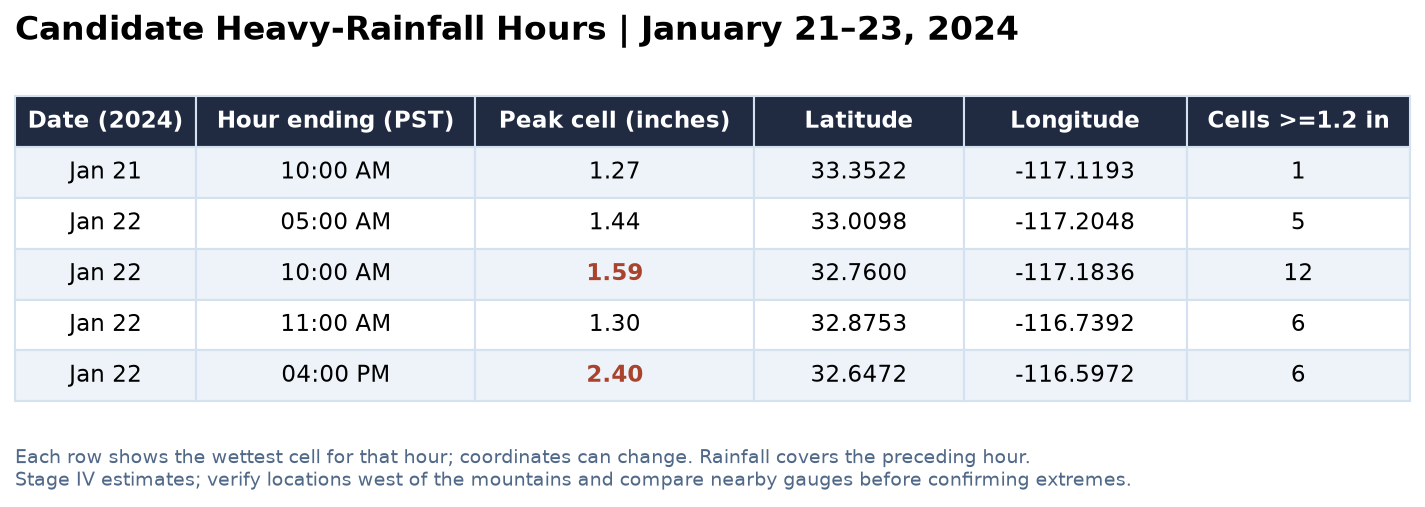

In [ ]:
# Filter actual observations at or above the lower 1-hour screening flag.
# Missing rainfall is excluded; these are candidate events, not gauge confirmations.
flagged_cells = rain.loc[
    rain["rainfall_inches"].notna() & (rain["rainfall_inches"] >= 1.2),
    ["hour_end_pacific", "rainfall_mm", "rainfall_inches", "latitude", "longitude"]
].copy()

# One row per flagged hour: show its wettest cell, plus how many cells crossed 1.2 in.
peak_rows = flagged_cells.groupby("hour_end_pacific")["rainfall_inches"].idxmax()
peak_cells = flagged_cells.loc[peak_rows].sort_values("hour_end_pacific").copy()
counts = flagged_cells.groupby("hour_end_pacific").size()
peak_cells["cells_at_or_above_1_2_in"] = peak_cells.hour_end_pacific.map(counts)

screening_table = pd.DataFrame({
    "Date (2024)": peak_cells.hour_end_pacific.dt.strftime("%b %d"),
    "Hour ending (PST)": peak_cells.hour_end_pacific.dt.strftime("%I:%M %p"),
    "Peak cell (inches)": peak_cells.rainfall_inches.round(2),
    "Latitude": peak_cells.latitude.round(4),
    "Longitude": peak_cells.longitude.round(4),
    "Cells >=1.2 in": peak_cells.cells_at_or_above_1_2_in,
}).reset_index(drop=True)

print(f"{len(flagged_cells)} grid-cell hours meet >=1.2 inches across {len(screening_table)} hours.")
display(screening_table)

# Save a slide-ready image of the same filtered values.
fig, ax = plt.subplots(figsize=(12, 3.3))
ax.axis("off")
ax.set_title("Candidate Heavy-Rainfall Hours | January 21–23, 2024", loc="left", fontsize=16, weight="bold", pad=18)
formatted = screening_table.copy()
formatted["Peak cell (inches)"] = formatted["Peak cell (inches)"].map("{:.2f}".format)
for col in ["Latitude", "Longitude"]:
    formatted[col] = formatted[col].map("{:.4f}".format)
table = ax.table(cellText=formatted.values, colLabels=formatted.columns,
                 cellLoc="center", bbox=[0, 0.15, 1, 0.8],
                 colWidths=[0.13, 0.20, 0.20, 0.15, 0.16, 0.16])
table.auto_set_font_size(False)
table.set_fontsize(11)
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#d3e1f1")
    if row == 0:
        cell.set_facecolor("#202a41"); cell.set_text_props(color="white", weight="bold")
    else:
        cell.set_facecolor("#edf3f8" if row % 2 else "white")
        if col == 2 and float(formatted.iloc[row-1, col]) >= 1.5:
            cell.set_text_props(color="#a9432e", weight="bold")
fig.text(0.125, 0.055,
         "Each row shows the wettest cell for that hour; coordinates can change. Rainfall covers the preceding hour.\n"
         "Stage IV estimates; verify locations west of the mountains and compare nearby gauges before confirming extremes.",
         fontsize=9, color="#516988")
fig.savefig(figures / "extreme_rainfall_filtered_values.png", dpi=200, bbox_inches="tight")
plt.show()
